# Lab: customer segmentation with RFM and k-means

The shop is a UK online retailer of gifts; many of its customers are wholesalers. One row of the raw table is one product line on one invoice. The marketing lead: "We send the same email to everyone. Give me a few groups of customers that behave differently, say how big each one is, and what you would send each."

Work through the checkpoints in order. C1 is the minimum, C2 is today's target, C3 is for those who finish C2.

## The starter

The cell loads the year from 2010-12-01 to 2011-12-09 with `Invoice` and `StockCode` read as text (an invoice number like `C536379` is not a number), and lists the stock codes that are not products. The renames make older downloads of the file use the same column names.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

raw = pd.read_csv("data/online_retail_ii.csv", dtype={"Invoice": str, "StockCode": str, "InvoiceNo": str})
raw = raw.rename(columns={"InvoiceNo": "Invoice", "UnitPrice": "Price", "CustomerID": "Customer ID"})
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"])
raw = raw[raw["InvoiceDate"] >= "2010-12-01"].reset_index(drop=True)

# Stock codes that are postage, fees, manual adjustments or tests, not products
NON_PRODUCT = {"POST", "D", "M", "C2", "DOT", "BANK CHARGES", "PADS", "CRUK", "AMAZONFEE", "S", "B", "ADJUST",
               "ADJUST2", "TEST001", "TEST002", "GIFT"}
print(len(raw), "rows from", raw["InvoiceDate"].min().date(), "to", raw["InvoiceDate"].max().date())
raw.head()

541910 rows from 2010-12-01 to 2011-12-09


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## C1 · One row per customer

### Step 1 · Clean the rows, one rule at a time

Count what each rule removes: rows with no `Customer ID`; cancellations (`Invoice` starts with `C`); rows with `Quantity` or `Price` not above 0; stock codes in `NON_PRODUCT`.

In [2]:
removed = {}
df = raw
keep = df["Customer ID"].notna()
removed["no Customer ID"], df = (~keep).sum(), df[keep]
keep = ~df["Invoice"].str.startswith("C")
removed["cancellations"], df = (~keep).sum(), df[keep]
keep = (df["Quantity"] > 0) & (df["Price"] > 0)
removed["quantity or price not above 0"], df = (~keep).sum(), df[keep]
keep = ~df["StockCode"].str.upper().isin(NON_PRODUCT)
removed["not a product"], df = (~keep).sum(), df[keep].copy()
df["Customer ID"] = df["Customer ID"].astype(int)
for rule, n in removed.items():
    print(f"{rule:<32} {n:>7,} rows removed")
print(f"{'left':<32} {len(df):>7,} rows")

no Customer ID                   135,080 rows removed
cancellations                      8,905 rows removed
quantity or price not above 0         40 rows removed
not a product                      1,548 rows removed
left                             396,337 rows


### Step 2 · Revenue and the snapshot date

Add `Revenue = Quantity * Price`. Set `snapshot` to the day after the last invoice.

In [3]:
df["Revenue"] = df["Quantity"] * df["Price"]
snapshot = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
snapshot.date()

datetime.date(2011, 12, 10)

### Step 3 · The RFM table

Group by `Customer ID`: **Recency** (days from the customer's last invoice to `snapshot`), **Frequency** (distinct invoices), **Monetary** (total revenue).

In [4]:
g = df.groupby("Customer ID").agg(last=("InvoiceDate", "max"), Frequency=("Invoice", "nunique"),
                                  Monetary=("Revenue", "sum"))
rfm = pd.DataFrame({"Recency": (snapshot - g["last"]).dt.days, "Frequency": g["Frequency"], "Monetary": g["Monetary"]})
print(len(rfm), "customers")
rfm.median()

4334 customers


Recency       50.000
Frequency      2.000
Monetary     668.125
dtype: float64

## C2 · Cluster and choose k

### Step 4 · Look, then log and scale

Look at the three columns with `describe()` and `skew()`. Then build `prep = make_pipeline(FunctionTransformer(np.log1p), StandardScaler())` and `Z = prep.fit_transform(rfm)`.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

print(rfm.describe().round(1))
print("skew before the log:", rfm.skew().round(3).to_dict())
print("skew after the log: ", np.log1p(rfm).skew().round(3).to_dict())
prep = make_pipeline(FunctionTransformer(np.log1p), StandardScaler())
Z = prep.fit_transform(rfm)

       Recency  Frequency  Monetary
count   4334.0     4334.0    4334.0
mean      92.2        4.2    2021.5
std      100.2        7.6    8907.5
min        0.0        1.0       3.8
25%       17.0        1.0     305.6
50%       50.0        2.0     668.1
75%      142.0        5.0    1631.6
max      373.0      206.0  279138.0
skew before the log: {'Recency': 1.243, 'Frequency': 11.949, 'Monetary': 19.564}
skew after the log:  {'Recency': -0.467, 'Frequency': 1.214, 'Monetary': 0.396}


### Step 5 · Inertia and silhouette for k = 2 to 10

Fit `KMeans(n_clusters=k, n_init=10, random_state=42)` on `Z` and record `inertia_` and `silhouette_score(Z, labels)`. Plot both against k.

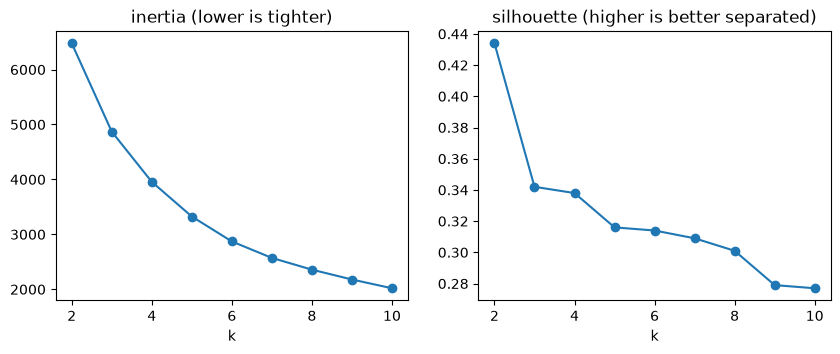

,inertia,silhouette
k,,
2,6479.0,0.434
3,4869.1,0.342
4,3955.7,0.338
5,3324.7,0.316
6,2870.9,0.314
7,2571.3,0.309
8,2357.4,0.301
9,2178.3,0.279
10,2019.1,0.277


In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    rows.append({"k": k, "inertia": round(km.inertia_, 1), "silhouette": round(silhouette_score(Z, km.labels_), 3)})
choose = pd.DataFrame(rows).set_index("k")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5))
choose["inertia"].plot(ax=a1, marker="o", title="inertia (lower is tighter)")
choose["silhouette"].plot(ax=a2, marker="o", title="silhouette (higher is better separated)")
plt.show()
choose

### Step 6 · "How many groups?"

Where the inertia curve bends, what the silhouette score says, and how many groups the team can act on. Fit the k you chose.

In [7]:
K = 4      # silhouette prefers 2 (recent against lapsed); 3 and 4 score almost the same, and 4 gives four actions
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z)
rfm["segment"] = km.labels_

## C3 · Name the segments

### Step 7 · Profile each segment

For your k: number of customers, median recency, median frequency, median monetary, and the segment's share of total revenue.

In [8]:
profile = rfm.groupby("segment").agg(customers=("Recency", "size"), recency=("Recency", "median"),
                                     frequency=("Frequency", "median"), monetary=("Monetary", "median"),
                                     revenue=("Monetary", "sum"))
profile["revenue_share"] = (profile["revenue"] / profile["revenue"].sum()).round(3)
profile = profile.drop(columns="revenue").sort_values("monetary", ascending=False)
profile

,customers,recency,frequency,monetary,revenue_share
segment,,,,,
2,689,8.0,10.0,3735.470,0.641
3,1182,53.0,4.0,1357.605,0.242
0,815,16.0,2.0,471.780,0.051
1,1648,173.0,1.0,296.725,0.065


### Step 8 · Name each segment and give it an action

A table with four columns: name, size, what they look like, what to send.

In [9]:
names = ["Best customers", "Regulars", "New or occasional", "Lapsed"]
actions = ["Early access and a named contact; protect, do not discount",
           "A reorder reminder timed to their usual gap between orders",
           "A welcome series and a second-order offer",
           "One win-back offer, then stop emailing if nothing comes back"]
plan = pd.DataFrame({"name": names, "size": profile["customers"].values,
                     "what they look like": [f"last bought {int(r.recency)} days ago, {int(r.frequency)} orders, "
                                             f"{round(r.monetary):,} spent (medians)" for r in profile.itertuples()],
                     "what to send": actions})
plan

,name,size,what they look like,what to send
0,Best customers,689,"last bought 8 days ago, 10 orders, 3,735 spent...","Early access and a named contact; protect, do ..."
1,Regulars,1182,"last bought 53 days ago, 4 orders, 1,358 spent...",A reorder reminder timed to their usual gap be...
2,New or occasional,815,"last bought 16 days ago, 2 orders, 472 spent (...",A welcome series and a second-order offer
3,Lapsed,1648,"last bought 173 days ago, 1 orders, 297 spent ...","One win-back offer, then stop emailing if noth..."


## Bonus · k-means on the raw columns

In [10]:
raw_km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(rfm[["Recency", "Frequency", "Monetary"]])
raw_sizes = sorted(np.bincount(raw_km.labels_), reverse=True)
print("cluster sizes, no log, no scaling:", raw_sizes)
print("standard deviation:", rfm[["Recency", "Frequency", "Monetary"]].std().round(1).to_dict())

cluster sizes, no log, no scaling: [np.int64(4296), np.int64(31), np.int64(5), np.int64(2)]
standard deviation: {'Recency': 100.2, 'Frequency': 7.6, 'Monetary': 8907.5}


## Check yourself

In [11]:
check = {
    "Starter · rows": len(raw),
    "Step 1 · no Customer ID": removed["no Customer ID"],
    "Step 1 · cancellations": removed["cancellations"],
    "Step 1 · quantity or price not above 0": removed["quantity or price not above 0"],
    "Step 1 · not a product": removed["not a product"],
    "Step 1 · rows left": len(df),
    "Step 3 · customers": len(rfm),
    "Step 3 · snapshot": snapshot.date(),
    "Step 3 · median recency": rfm["Recency"].median(),
    "Step 3 · median frequency": rfm["Frequency"].median(),
    "Step 3 · median monetary": round(rfm["Monetary"].median(), 1),
}
for col in ("Recency", "Frequency", "Monetary"):
    check[f"Step 4 · {col} skew before"] = round(rfm[col].skew(), 3)
    check[f"Step 4 · {col} skew after"] = round(np.log1p(rfm[col]).skew(), 3)
for k in (2, 3, 4, 10):
    check[f"Step 5 · k={k}"] = f"inertia {choose.loc[k, 'inertia']}, silhouette {choose.loc[k, 'silhouette']}"
for seg, r in profile.iterrows():
    check[f"Step 7 · segment label {seg}"] = (f"{int(r.customers)} customers, median recency {int(r.recency)} days, "
                                              f"frequency {int(r.frequency)}, monetary {round(r.monetary)}, "
                                              f"revenue share {r.revenue_share:.3f}")
check["Bonus · raw cluster sizes"] = ", ".join(map(str, raw_sizes))
check["Bonus · standard deviations"] = ", ".join(f"{c} {rfm[c].std():.1f}" for c in ("Recency", "Frequency", "Monetary"))
for label, value in check.items():
    print(f"{label:<38} {value}")

Starter · rows                         541910
Step 1 · no Customer ID                135080
Step 1 · cancellations                 8905
Step 1 · quantity or price not above 0 40
Step 1 · not a product                 1548
Step 1 · rows left                     396337
Step 3 · customers                     4334
Step 3 · snapshot                      2011-12-10
Step 3 · median recency                50.0
Step 3 · median frequency              2.0
Step 3 · median monetary               668.1
Step 4 · Recency skew before           1.243
Step 4 · Recency skew after            -0.467
Step 4 · Frequency skew before         11.949
Step 4 · Frequency skew after          1.214
Step 4 · Monetary skew before          19.564
Step 4 · Monetary skew after           0.396
Step 5 · k=2                           inertia 6479.0, silhouette 0.434
Step 5 · k=3                           inertia 4869.1, silhouette 0.342
Step 5 · k=4                           inertia 3955.7, silhouette 0.338
Step 5 · k=10    